# 컨베이어 카운터 오작동 리셋 — 대차 번호별 집계 (2026-10-13 ~ 10-14)

카운터는 정상이면 130~140 까지 올라간 뒤 리셋된다. 센서가 대차 한 대 지나가는 동안 두 번 이상 켜지면 카운트가 중간에 다시 떨어진다 → **오작동 리셋**.

| 규칙 | 내용 |
|---|---|
| 카운터 | Pour_Zone, Conv_Stop, MD_CY_FWD, Opening, Closing, MD_CY_REV(10/14 추가) |
| 기준 사이클 | `Pour_Zone_CNT PV` 리셋 → 다음 리셋. 이 순간 `Now_Actual_Wagon_Num` 도 바뀐다(아래 셀에서 확인) |
| 제외 | 다섯 카운터 중 하나라도 **30초 이상 값이 그대로**인 구간이 걸친 Pour 사이클은 통째로 뺀다. 첫 Pour 리셋 전·마지막 미완성 사이클도 뺀다 |
| 오작동 리셋 | 카운트가 감소했는데 직전 값이 **100 이하** (정상 리셋은 직전 값 100 이상, 대부분 130~145) |
| 통과 1회 | 정상 리셋 1개 + 바로 뒤따르는 오작동 리셋들. 리셋이 2개 이상이면 **오작동 통과** |
| 대차 번호 붙이기 | 통과의 첫 리셋 시각이 들어가는 Pour 사이클의 대차 번호. **MD_CY_FWD 만** 첫 리셋이 Pour 리셋 ±1.5초에 생겨서(대차마다 앞/뒤가 다름) 6초 밀어 '가장 가까운 Pour 리셋'의 번호를 붙인다 |

**대차 번호 = 실제 대차 번호.** 카운터마다 센서 앞에 있는 실제 대차로 바꿔 붙였다(`conv_wagon_reset.LABEL_OFFSET`, 근거는 기간추이 노트북 9절).
MD_CY_FWD·MD_CY_REV 는 '1번감지' 센서로, Opening 은 'Opening 다음 바로 전진Unit 에 같은 대차' 로 확인했고, Conv_Stop·Closing 은 대차 간격 무늬로 맞춘 값이다. `pour_wagon` 열은 Pour 기준 번호다.

`후진Unit 캐리어 진입감지` 는 공백 수만 다른 태그가 두 개다(`후진Unit␣␣캐리어␣␣진입감지`, `후진Unit␣␣캐리어␣진입감지`). 값이 99.75% 같고 리셋 때 켜지는 비율도 같아서 앞의 것을 쓴다(4번 셀 아래에서 비교).


In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("../.."))   # Log_Extractor
import importlib, conv_wagon_reset as cw
importlib.reload(cw)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_rows", 60)
plt.rc("font", family="Malgun Gothic" if os.name == "nt" else "AppleGothic"); plt.rc("axes", unicode_minus=False)

START, END = "2026-10-13 00:00:00", "2026-10-14 15:18:37"   # KST
CACHE = "../cache/conv_wagon_reset"; OUT = "../analysis_out/conv_wagon_reset"
os.makedirs(CACHE, exist_ok=True); os.makedirs(OUT, exist_ok=True)
df = cw.pull(START, END, f"{CACHE}/df_20261013_14_v2.pkl")
print(df.shape, df.index.min(), "~", df.index.max())

(167291, 15) 2026-10-13 00:00:00.233546 ~ 2026-10-14 15:18:36.667883


## 1. 기준 확인 — Pour 리셋 순간에 대차 번호가 바뀌는가

In [2]:
P = df[cw.COUNTERS["Pour_Zone"][0]]
pour_reset = df.index[np.r_[False, P.values[1:] < P.values[:-1]]]
w = df[cw.WAGON]; wchg = df.index[(w.diff() != 0) & w.shift().notna()]
lag = pd.Series([(t - pour_reset[max(pour_reset.searchsorted(t, side="right") - 1, 0)]).total_seconds() for t in wchg])
print(f"Pour 리셋 {len(pour_reset)}번, 대차 번호 변경 {len(wchg)}번")
print("대차 번호가 바뀐 시각 - 직전 Pour 리셋 (초):"); display(lag.round(1).value_counts().sort_index().to_frame("건수"))

Pour 리셋 6622번, 대차 번호 변경 6621번
대차 번호가 바뀐 시각 - 직전 Pour 리셋 (초):


,건수
0.0,5390
0.4,1
0.5,1212
0.6,16
0.7,1
2.1,1


## 2. 30초 정지 구간 제외

In [3]:
flats = cw.find_flats(df)
cyc = cw.pour_cycles(df, flats)
display(flats.groupby("counter")["sec"].agg(구간수="size", 합계_분=lambda s: round(s.sum() / 60, 1)))
k = cyc[~cyc["flat"]]
print(f"Pour 사이클 {len(cyc)}개 중 제외 {int(cyc['flat'].sum())}개 → 남김 {len(k)}개")
print("남긴 사이클 대차 번호가 +1 씩 이어지나:", (cyc["wagon"].diff() % 42).value_counts().to_dict())
display(k[["dur_s", "pour_max"]].describe().T.round(2))

,구간수,합계_분
counter,,
(DB 빈 구간),207,913.4
Closing,31,917.9
Conv_Stop,31,917.9
MD_CY_FWD,31,917.9
MD_CY_REV,31,917.9
Opening,31,917.9
Pour_Zone,31,917.9


Pour 사이클 6621개 중 제외 29개 → 남김 6592개
남긴 사이클 대차 번호가 +1 씩 이어지나: {1.0: 6620}


,count,mean,std,min,25%,50%,75%,max
dur_s,6592.0,13.04,1.10,11.93,12.37,12.54,12.91,25.12
pour_max,6592.0,137.43,2.22,117.00,136.00,137.00,139.00,144.00


## 3. 전제 확인 — 남긴 Pour 사이클마다 카운터별 통과가 정확히 한 번인가
키: 사이클 안 통과 횟수, 값: 사이클 수

In [4]:
R = {n: cw.counter_resets(df, n, cyc) for n in cw.COUNTERS}
B = {n: cw.bursts(R[n]) for n in cw.COUNTERS}
display(pd.DataFrame({n: cw.per_cycle_check(cyc, B[n]) for n in cw.COUNTERS}).fillna(0).astype(int))

,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
1,6592,6592,6592,6592,6592,6592


## 4. 카운터별 요약
- `abn_passes`: 오작동 통과 수, `abn_pct`: 통과 대비 %, `abn_resets`: 오작동 리셋 개수(한 통과에 여러 번 떨어질 수 있음), `wagons_hit`: 한 번이라도 걸린 대차 수
- 아래 '리셋 직전 값' 분포에서 21~99 가 비어 있어서 기준을 20 으로 하든 100 으로 하든 결과가 같다.

In [5]:
S = cw.summary(cyc, B); display(S)
S.to_csv(f"{OUT}/summary.csv", encoding="utf-8-sig")
bins = [-1, 20, 99, 119, 129, 139, 149, 999]
display(pd.DataFrame({n: pd.cut(R[n].loc[~R[n]["flat"], "before"], bins).value_counts().sort_index() for n in cw.COUNTERS}))
sig = pd.DataFrame({n: R[n][~R[n]["flat"]].groupby("abnormal")["sig_near"].mean().mul(100).round(1) for n in cw.COUNTERS}).T
sig.columns = ["정상 리셋 때 DB 에 센서 ON 보임(%)", "오작동 리셋 때 DB 에 센서 ON 보임(%)"][:len(sig.columns)]
display(sig)

,pour_cycles,passes,abn_passes,abn_pct,abn_resets,wagons_hit
counter,,,,,,
Pour_Zone,6592,6592,0,0.00,0,0
Conv_Stop,6592,6592,0,0.00,0,0
MD_CY_FWD,6592,6592,1669,25.32,2547,18
Opening,6592,6592,73,1.11,73,1
Closing,6592,6592,0,0.00,0,0
MD_CY_REV,6592,6592,130,1.97,150,3


,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
before,,,,,,
"(-1, 20]",0,0,2547,73,0,150
"(20, 99]",0,0,0,0,0,0
"(99, 119]",3,2,14,0,0,0
"(119, 129]",3,5,1506,72,7,176
"(129, 139]",5566,5608,4425,5527,5498,5460
"(139, 149]",1020,977,647,993,1087,956
"(149, 999]",0,0,0,0,0,0


,정상 리셋 때 DB 에 센서 ON 보임(%),오작동 리셋 때 DB 에 센서 ON 보임(%)
Pour_Zone,55.3,NaN
Conv_Stop,56.4,NaN
MD_CY_FWD,69.7,93.3
Opening,62.4,98.6
Closing,60.3,NaN
MD_CY_REV,59.9,84.0


In [6]:
# 후진Unit 진입감지 태그 두 개 비교 — 리셋 순간(±1틱) DB 에 센서 ON 이 보인 비율
cmp = {}
for s in [cw.COUNTERS["MD_CY_REV"][1], *cw.EXTRA_SIG_TAGS]:
    rr = cw.counter_resets(df, "MD_CY_REV", cyc, sig=s); rr = rr[~rr["flat"]]
    cmp[repr(s)] = rr.groupby("abnormal")["sig_near"].mean().mul(100).round(1).rename({False: "정상 리셋 %", True: "오작동 리셋 %"})
display(pd.DataFrame(cmp).T)
a, b = df[cw.COUNTERS["MD_CY_REV"][1]], df[cw.EXTRA_SIG_TAGS[0]]
print("두 태그 값이 같은 행 비율:", round((a == b).mean() * 100, 2), "%")

abnormal,정상 리셋 %,오작동 리셋 %
'후진Unit 캐리어 진입감지',59.9,84.0
'후진Unit 캐리어 진입감지',60.2,82.7


두 태그 값이 같은 행 비율: 99.75 %


## 5. 대차 번호별 — 오작동이 있는 카운터만

In [7]:
HIT = [n for n in cw.COUNTERS if S.loc[n, "abn_passes"] > 0]
WT = {n: cw.wagon_table(cyc, B[n]) for n in HIT}
for n in HIT:
    WT[n].to_csv(f"{OUT}/wagon_{n}.csv", encoding="utf-8-sig")
    print(f"■ {n} — 오작동 비율 높은 순")
    t = WT[n][WT[n]["abn_passes"] > 0].sort_values(["abn_pct", "abn_resets"], ascending=False)
    display(t.join(cw.wagon_by_date(B[n]).add_prefix("pct_")))

■ MD_CY_FWD — 오작동 비율 높은 순


,passes,abn_passes,abn_pct,abn_resets,p_value,pct_2026-10-13,pct_2026-10-14
wagon,,,,,,,
13,158,158,100.0,309,5.538393e-95,100.0,100.0
10,158,158,100.0,296,5.538393e-95,100.0,100.0
35,157,157,100.0,252,2.187483e-94,100.0,100.0
30,157,157,100.0,247,2.187483e-94,100.0,100.0
23,157,156,99.4,304,1.015207e-91,100.0,98.1
42,157,156,99.4,181,1.015207e-91,100.0,98.1
19,157,154,98.1,203,3.575383e-87,99.0,96.2
32,158,140,88.6,146,3.555943e-63,94.3,77.4
16,156,132,84.6,249,1.864381e-54,100.0,54.7


■ Opening — 오작동 비율 높은 순


,passes,abn_passes,abn_pct,abn_resets,p_value,pct_2026-10-13,pct_2026-10-14
wagon,,,,,,,
20,157,73,46.5,73,5.397646e-98,52.9,34.0


■ MD_CY_REV — 오작동 비율 높은 순


,passes,abn_passes,abn_pct,abn_resets,p_value,pct_2026-10-13,pct_2026-10-14
wagon,,,,,,,
16,157,76,48.4,90,5.670825e-85,57.7,30.2
9,157,51,32.5,57,9.158348e-47,43.3,11.3
13,156,3,1.9,3,5.960604e-01,1.0,3.8


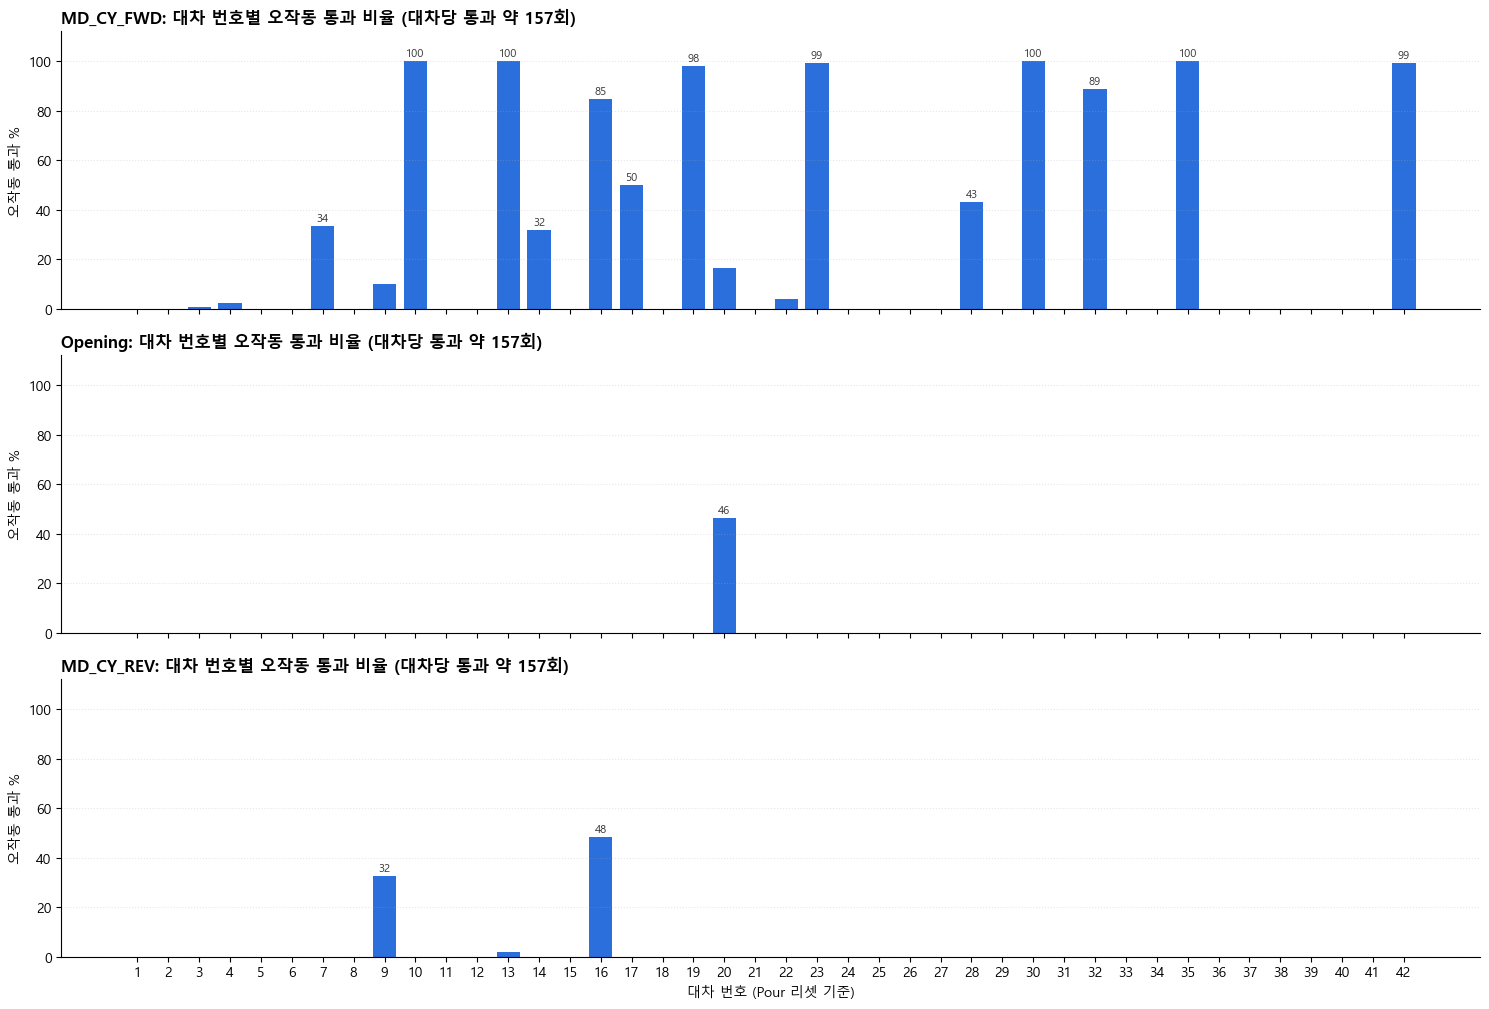

In [8]:
fig, ax = plt.subplots(len(HIT), 1, figsize=(15, 3.4 * len(HIT)), sharex=True)
ax = np.atleast_1d(ax)
for a, n in zip(ax, HIT):
    t = WT[n]
    a.bar(t.index, t["abn_pct"].fillna(0), width=0.75, color="#2a6fdb")
    for wg, v in t["abn_pct"].items():
        if v >= 30:
            a.text(wg, v + 2, f"{v:.0f}", ha="center", fontsize=8, color="#333")
    a.set_ylim(0, 112); a.set_ylabel("오작동 통과 %")
    a.set_title(f"{n}: 대차 번호별 오작동 통과 비율 (대차당 통과 약 157회)", fontweight="bold", loc="left")
    a.grid(axis="y", alpha=0.3, ls=":"); a.spines[["top", "right"]].set_visible(False)
ax[-1].set_xticks(range(1, 43)); ax[-1].set_xlabel("대차 번호 (Pour 리셋 기준)")
fig.tight_layout(); fig.savefig(f"{OUT}/wagon_bar.png", dpi=100)

## 6. 시간에 따라 바뀌었나 — 대차 × 2시간 오작동 비율
빈 칸은 그 시간에 가동하지 않은 것.

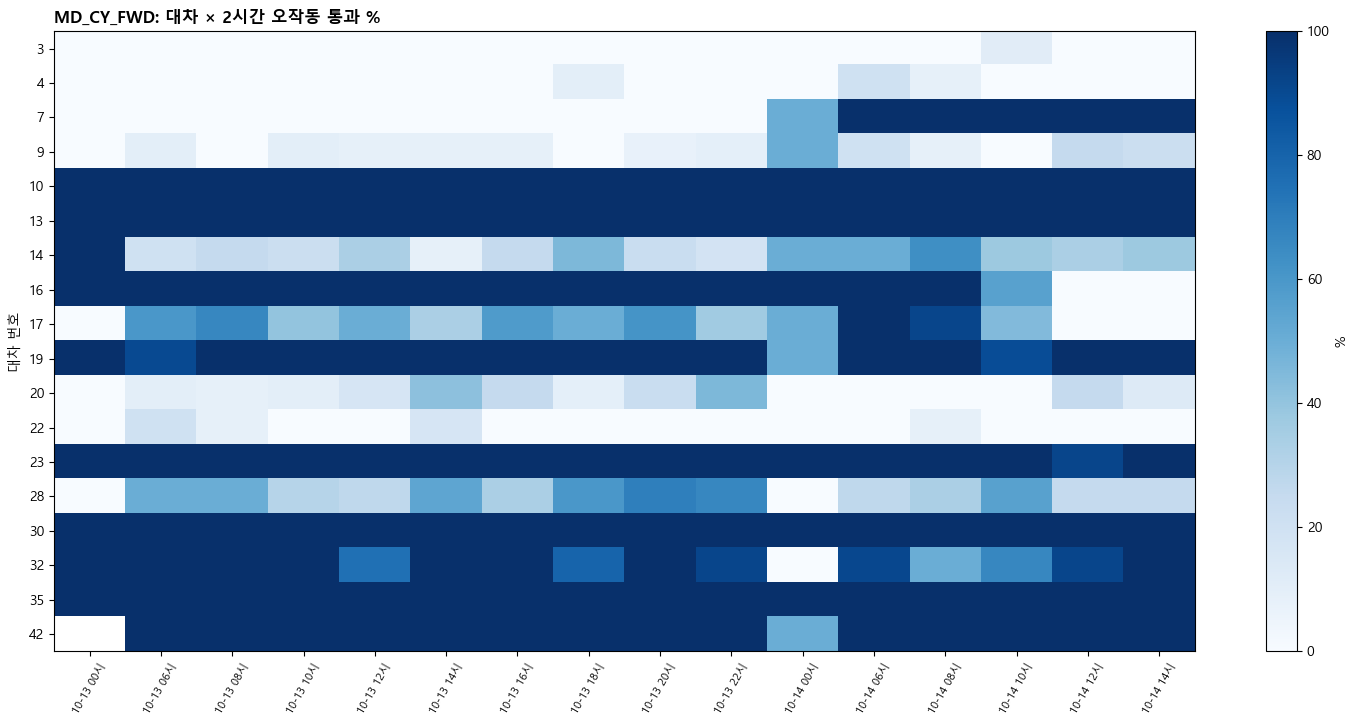

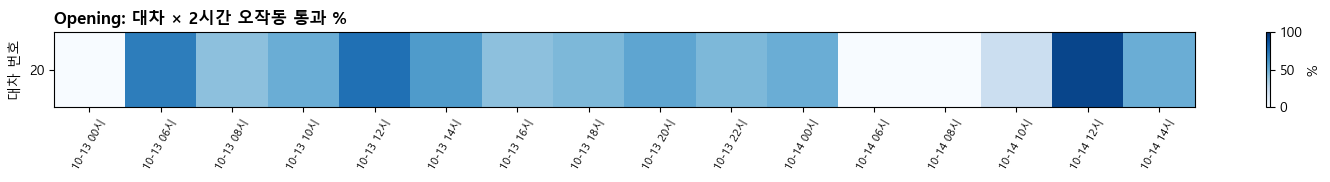

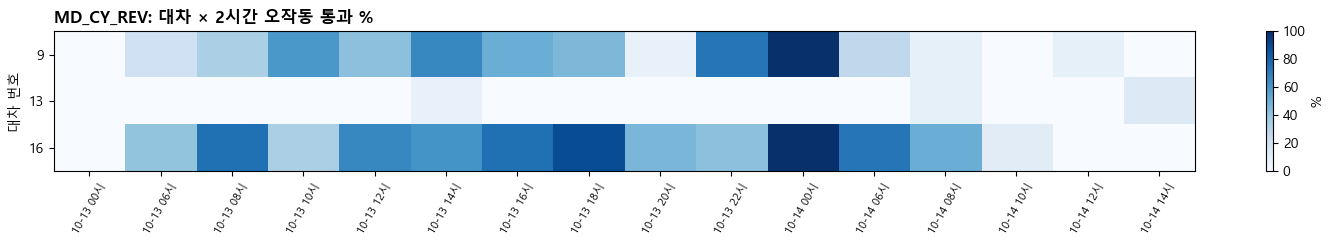

In [9]:
for n in HIT:
    b = B[n][~B[n]["flat"]].copy()
    b["bin"] = b["time"].dt.floor("2h")
    piv = b.pivot_table(index="wagon", columns="bin", values="abnormal", aggfunc="mean").mul(100)
    piv = piv.loc[WT[n].index[WT[n]["abn_passes"] > 0]]
    fig, a = plt.subplots(figsize=(15, 0.32 * len(piv) + 1.6))
    im = a.imshow(piv.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
    a.set_yticks(range(len(piv))); a.set_yticklabels(piv.index)
    a.set_xticks(range(piv.shape[1])); a.set_xticklabels(piv.columns.strftime("%m-%d %H시"), rotation=60, fontsize=8)
    a.set_ylabel("대차 번호"); a.set_title(f"{n}: 대차 × 2시간 오작동 통과 %", fontweight="bold", loc="left")
    fig.colorbar(im, ax=a, label="%"); fig.tight_layout(); fig.savefig(f"{OUT}/wagon_time_{n}.png", dpi=100)

## 7. 원본 확인 — 오작동 통과와 정상 통과 실제 값
카운터·센서·Pour 카운트를 통과 첫 리셋 앞뒤로 보여준다. 직접 시각을 바꿔서 보면 된다.

**표 읽는 법:** 표의 `Now_Actual_Wagon_Num` 은 그 순간 **Pour 에 있는** 대차 번호라서 제목의 실제 번호와 다르다(MD_CY_FWD 는 27, Opening 은 26, MD_CY_REV 는 41 차이). MD_CY_FWD 통과는 Pour 리셋 ±1.5초에 생겨서 가장 가까운 Pour 리셋 기준으로 센다.

In [10]:
def show_pass(name, wagon, nth=0, abnormal=True, before=3, after=6):
    cnt, sig = cw.COUNTERS[name]
    b = B[name]; b = b[(~b["flat"]) & (b["wagon"] == wagon) & (b["abnormal"] == abnormal)]
    if b.empty:
        print(f"{name} 대차 {wagon}: 해당 통과 없음"); return
    t0 = b["time"].iloc[nth]; i = df.index.get_loc(t0)
    out = df.iloc[i - before:i + after][[cw.COUNTERS["Pour_Zone"][0], cnt, sig, cw.WAGON]]
    out.index = out.index.strftime("%m-%d %H:%M:%S.%f").str[:-4]
    print(f"■ {name} 대차 {wagon} ({'오작동' if abnormal else '정상'})"); display(out)

top = {n: int(WT[n]["abn_pct"].idxmax()) for n in HIT}
for n in HIT:
    show_pass(n, top[n], abnormal=True)
    show_pass(n, top[n], abnormal=False)
show_pass("MD_CY_FWD", 3, abnormal=False)

■ MD_CY_FWD 대차 10 (오작동)


,Pour_Zone_CNT PV,MD_CY_FWD_Zone_CNT PV,전진Unit 캐리어 진입감지,Now_Actual_Wagon_Num
Time,,,,
10-13 00:20:47.73,115,114.0,0.0,36.0
10-13 00:20:48.28,121,120.0,0.0,36.0
10-13 00:20:48.77,126,125.0,0.0,36.0
10-13 00:20:49.31,132,2.0,1.0,36.0
10-13 00:20:49.82,138,1.0,0.0,36.0
10-13 00:20:50.36,5,7.0,1.0,37.0
10-13 00:20:50.90,9,4.0,1.0,37.0
10-13 00:20:51.42,13,8.0,0.0,37.0
10-13 00:20:51.94,18,13.0,0.0,37.0


MD_CY_FWD 대차 10: 해당 통과 없음
■ Opening 대차 20 (오작동)


,Pour_Zone_CNT PV,Opening_CNT PV,Opening Zone In Detect,Now_Actual_Wagon_Num
Time,,,,
10-13 06:33:01.13,78,115.0,0.0,4.0
10-13 06:33:01.67,85,122.0,0.0,4.0
10-13 06:33:02.18,90,127.0,0.0,4.0
10-13 06:33:02.69,96,2.0,0.0,4.0
10-13 06:33:03.22,102,8.0,1.0,4.0
10-13 06:33:03.75,108,7.0,0.0,4.0
10-13 06:33:04.26,113,12.0,0.0,4.0
10-13 06:33:04.79,119,18.0,0.0,4.0
10-13 06:33:05.33,125,24.0,0.0,4.0


■ Opening 대차 20 (정상)


...

,Pour_Zone_CNT PV,MD_CY_REV_Zone_CNT PV,후진Unit 캐리어 진입감지,Now_Actual_Wagon_Num
Time,,,,
10-13 06:53:24.08,130,113.0,0.0,14.0
10-13 06:53:24.59,136,119.0,0.0,14.0
10-13 06:53:25.13,4,125.0,0.0,15.0
10-13 06:53:25.66,10,6.0,1.0,15.0
10-13 06:53:26.17,15,4.0,1.0,15.0
10-13 06:53:26.68,21,3.0,1.0,15.0
10-13 06:53:27.22,27,9.0,0.0,15.0
10-13 06:53:27.76,33,15.0,0.0,15.0
10-13 06:53:28.26,39,21.0,0.0,15.0


■ MD_CY_REV 대차 16 (정상)


,Pour_Zone_CNT PV,MD_CY_REV_Zone_CNT PV,후진Unit 캐리어 진입감지,Now_Actual_Wagon_Num
Time,,,,
10-13 00:00:17.97,134,117.0,0.0,14.0
10-13 00:00:18.51,2,123.0,0.0,14.0
10-13 00:00:19.02,7,128.0,0.0,15.0
10-13 00:00:19.54,13,2.0,0.0,15.0
10-13 00:00:20.07,19,2.0,0.0,15.0
10-13 00:00:20.60,25,8.0,0.0,15.0
10-13 00:00:21.11,30,13.0,0.0,15.0
10-13 00:00:21.63,36,19.0,0.0,15.0
10-13 00:00:22.17,42,25.0,0.0,15.0


■ MD_CY_FWD 대차 3 (정상)


,Pour_Zone_CNT PV,MD_CY_FWD_Zone_CNT PV,전진Unit 캐리어 진입감지,Now_Actual_Wagon_Num
Time,,,,
10-13 00:13:02.02,116,127.0,0.0,29.0
10-13 00:13:02.56,121,132.0,0.0,29.0
10-13 00:13:03.09,127,138.0,0.0,29.0
10-13 00:13:03.60,132,3.0,1.0,29.0
10-13 00:13:04.10,137,8.0,0.0,29.0
10-13 00:13:04.63,4,13.0,0.0,30.0
10-13 00:13:05.15,10,19.0,0.0,30.0
10-13 00:13:05.66,16,25.0,0.0,30.0
10-13 00:13:06.18,22,31.0,0.0,30.0


In [11]:
# 전체 오작동 리셋 목록 저장
pd.concat([R[n][R[n]["abnormal"] & ~R[n]["flat"]] for n in HIT]).to_csv(f"{OUT}/abnormal_resets.csv", index=False, encoding="utf-8-sig")
print(os.listdir(OUT))

['abnormal_resets.csv', 'period', 'summary.csv', 'wagon_bar.png', 'wagon_MD_CY_FWD.csv', 'wagon_MD_CY_REV.csv', 'wagon_Opening.csv', 'wagon_time_MD_CY_FWD.png', 'wagon_time_MD_CY_REV.png', 'wagon_time_Opening.png']
